# Model for combined covariate feature - initial years

## Environment setup

In [1]:
from pathlib import Path

# Data handling
import numpy as np
import pandas as pd

from scipy.stats import uniform, lognorm, gamma, randint

# Plotting
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
import seaborn as sns
import imgkit

# Time series feature engineering
from tsfresh.utilities.dataframe_functions import roll_time_series
from tsfresh import extract_features, select_features, extract_relevant_features
from tsfresh.utilities.dataframe_functions import impute

# Forecasting
from sklearn.metrics import make_scorer, max_error
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, MinMaxScaler, MaxAbsScaler, PowerTransformer, FunctionTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, GradientBoostingRegressor
from sklearn.linear_model import Lasso, Ridge
from sklearn.decomposition import PCA
import xgboost as xgb

# Optimization
import optuna
from skopt import BayesSearchCV
from skopt.space import Real, Integer, Categorical
from skopt.plots import plot_convergence, plot_objective
from mlforecast import MLForecast
from mlforecast.auto import (
    AutoMLForecast,
    AutoModel,
)
# Explaining
import shap
from skore import CrossValidationReport, EstimatorReport
# from interpret import show
# from interpret.glassbox import ExplainableBoostingRegressor

In [2]:
seed = sum(map(ord, "Covariate models extension, version 2 - Uvira")) 
rng = np.random.default_rng(seed = seed)

## Folder Structure

In [3]:
raw_data_dir = Path("../../data/raw")
processed_data_dir = Path("../../data/processed")
img_dir = Path("../../images")
img_dir.mkdir(exist_ok=True)

## Functions

In [4]:
def custom_smape(y_true, y_pred):
    tol = 1e-8
    smape = np.mean(200* np.abs(y_true - y_pred) / (np.abs(y_true) + np.abs(y_pred) + tol), axis=0)
    return smape

# Aggregation functions
def na_sum(x):
    if all(x.isna()):
        return np.nan
    else:
        return x.dropna().sum()

def na_log_sum(x):
    if all(x.isna()):
        return np.nan
    else:
        tot = x.dropna().sum()
        if tot > 0:
            return np.log(tot + 1)
        elif tot == 0:
            return 0
        else:
            return -np.log(-tot + 1)

def na_mean(x):
    if all(x.isna()):
        return np.nan
    else:
        return x.dropna().mean()


def standardize(x):
    return (x - x.mean()) / x.std()


def normalize(x):
    return (x - x.min()) / (x.max() - x.min())


def mask_target(x):
    """
    this mask returns an array of 1s where the last entry is a 0.
    Used to mask the rolled time series to avoid using the target in the features.
    """
    result = np.ones(len(x))
    result[-1] = 0
    return result


def xgbr_config(trial: optuna.Trial):
    return {
        "verbosity": 0,
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
        # "n_estimators": trial.suggest_int("n_estimators", 100, 500),
        # "max_depth": trial.suggest_int("max_depth", 3, 10),        
        # "alpha": trial.suggest_float("alpha", 1e-2, 1e2, log=True),
        # "reg_lambda": trial.suggest_float("reg_lambda", 1e-2, 1e2, log=True),
        # "min_split_loss": trial.suggest_int("min_split_loss", 1, 10),
    }

def init_config_simple(trial: optuna.Trial):
    return {}


def high_count_metric(y, y_pred, threshold=25):
    """
    A custom metric that prioritizes accuracy on high count values.
    """
    high_count_threshold = threshold  # Define a threshold for high count values
    high_count_mask = y > high_count_threshold

    low_error = np.mean(np.abs(y[~high_count_mask] - y_pred[~high_count_mask]))
    high_error = np.mean(2.2 * np.abs(y[high_count_mask] - y_pred[high_count_mask]))

    return high_error + low_error

## Import data

In [5]:
df = pd.read_csv(
    processed_data_dir / "uvira_full_data.csv",
    parse_dates=["date"]
)

In [6]:
df.head()

,date,reports,rdt_confirmed,vacc,vacc_prop,rainfall_mm,ssm,subssm,esi,lake_level,spei,num_conflicts,num_fatalities,num_disasters,num_disaster_affected,idps,covid_cases_per_million,covid_deaths_per_million
0,2016-04-15,6,0,0.0,0.0,12.001953,24.716246,139.518494,NaN,771.6340,NaN,0.0,0.0,0.0,0.0,NaN,0.0,0.0
1,2016-04-16,24,0,0.0,0.0,11.792500,24.885131,139.597733,NaN,771.6155,NaN,0.0,0.0,0.0,0.0,NaN,0.0,0.0
2,2016-04-17,17,0,0.0,0.0,8.569291,25.054015,139.676971,NaN,771.5970,NaN,0.0,0.0,0.0,0.0,NaN,0.0,0.0
3,2016-04-18,17,0,0.0,0.0,3.274265,25.222900,139.756210,NaN,771.5785,NaN,0.0,0.0,0.0,0.0,NaN,0.0,0.0
4,2016-04-19,6,0,0.0,0.0,7.377607,25.281933,140.015559,NaN,771.5600,NaN,0.0,0.0,0.0,0.0,NaN,0.0,0.0


## Parameters

In [7]:
START_DATE = "2016-05-01"
TEST_START_DATE = "2020-01-01"
TIME_BIN = 7
FORECAST_HORIZON = int(30 / TIME_BIN)

## Aggregate Data

In [8]:
df_weekly = (
    df
    .groupby(pd.Grouper(key = "date", freq = f"{TIME_BIN}D"), dropna=True)
    .agg({
        "reports": na_sum,
        "rdt_confirmed": na_sum,
        # "vacc_1": na_sum,
        # "vacc_1_prop": na_sum,
        # "vacc_2": na_sum,
        # "vacc_2_prop": na_sum,
        "vacc": na_sum,
        "vacc_prop": na_sum,
        "rainfall_mm": na_mean,
        "esi": na_mean,
        "lake_level": na_mean,
        "spei": na_mean,
        "num_fatalities": na_log_sum,
        "num_disaster_affected": na_sum,
        "idps": na_sum,
        "covid_cases_per_million": na_sum,
        "covid_deaths_per_million": na_sum
    })
    .assign(
        idps = lambda x: x["idps"].fillna(0)
    )
    .loc[lambda x: (
        (x.index >= START_DATE)
    )]
    .reset_index()
    .rename(columns = {
        "date": "ds",
        "reports": "y"
    })
)

In [9]:
df_weekly_for_model = (
    df_weekly
    .assign(
        unique_id = 1,
    )
    [[
        "unique_id",
        "ds",
        "y",
        "rainfall_mm",
        "esi",
        "lake_level",
        "spei",
        "num_fatalities",
        "num_disaster_affected",
    ]]
    .dropna()
    .reset_index(drop = True)
)

array([<Axes: xlabel='ds'>, <Axes: xlabel='ds'>, <Axes: xlabel='ds'>,
       <Axes: xlabel='ds'>, <Axes: xlabel='ds'>, <Axes: xlabel='ds'>,
       <Axes: xlabel='ds'>], dtype=object)

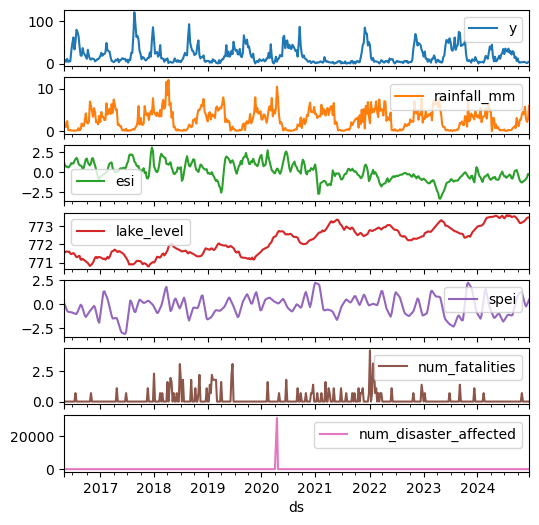

In [10]:
(
    df_weekly_for_model
    .drop(columns = ["unique_id"])
    .set_index("ds")
    .plot(subplots = True, figsize = (6, 6))
)

## Feature Engineering

### Create rolling datasets

Note that the rolling procedure includes the current timestamp so we need to drop the current value

In [11]:
lookback_period = 4
df_weekly_rolled = (
    roll_time_series(
        df_weekly_for_model.drop(columns=["y"]),
        column_id = "unique_id",
        column_sort = "ds",
        min_timeshift = lookback_period,
        max_timeshift = lookback_period
    )
    .drop(columns = ["unique_id"])
)

Rolling: 100%|██████████| 29/29 [00:02<00:00, 11.51it/s]


In [12]:
mask = (
    df_weekly_rolled
    .groupby("id")
    ["id"]
    .transform(mask_target)
    .astype(bool)
    .values
)

In [13]:
df_weekly_rolled_masked = (
    df_weekly_rolled
    .copy()
    [mask]
    .reset_index(drop = True)
)

### Build features

In [14]:
df_features = (
    extract_features(
        df_weekly_rolled_masked,
        column_id = "id",
        column_sort = "ds",
    )
    [lambda x: [c for c in x.columns if (x[c].isna().sum() == 0) & (x[c].std() > 0)]]
)

Feature Extraction: 100%|██████████| 30/30 [00:13<00:00,  2.31it/s]
/Users/paoich/miniforge3/envs/cholera-surveillance/lib/python3.12/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


In [15]:
df_ts_all_model_features = (
    impute(df_features)
    .reset_index()
    .drop(columns = ["level_0"])
    .rename(columns = {"level_1": "ds"})
    .dropna(axis = 1)
    [lambda x: [c for c in x.columns if not (("friedrich" in c) or ("benford" in c) or ("langevin" in c))]]
)

### Reduce feature with correlation

In [16]:
ts_relevant_features = [df_ts_all_model_features.columns.tolist()[0]]
for f in df_ts_all_model_features.columns.tolist()[1:]:
    corrs = df_ts_all_model_features[ts_relevant_features + [f]].corr()[f].abs()
    if corrs[:-1].max() < 0.3:
        ts_relevant_features.append(f)   

In [17]:
df_ts_final_model_features = df_ts_all_model_features[ts_relevant_features]

In [18]:
df_ts_final_model_features.shape

(447, 77)

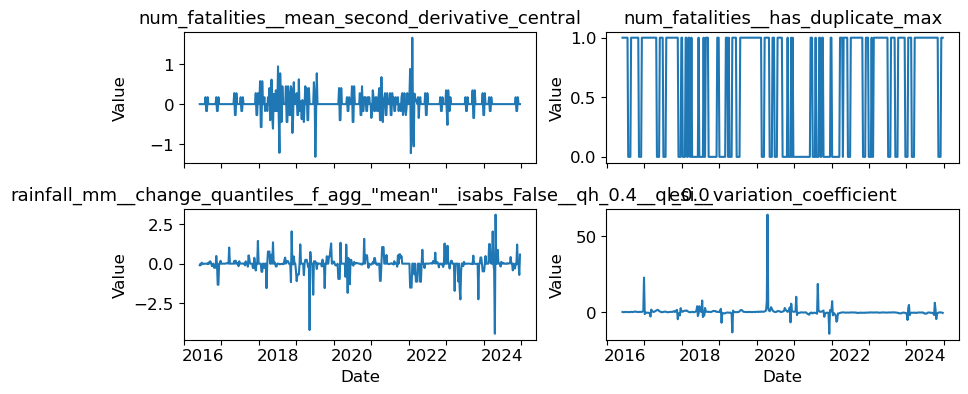

In [19]:
years = mdates.YearLocator(base = 1)
months = mdates.YearLocator(base = 2, month=7) 
yearsFmt = mdates.DateFormatter('\n%Y')
num_to_plot = 4
cols_to_plot = rng.choice(
    df_ts_final_model_features.columns.tolist(),
    size = num_to_plot,
    replace = False
)
ts_to_plot = (
    df_ts_final_model_features
    .set_index("ds")
    [cols_to_plot]
)

fig, axes = plt.subplots(
    int(num_to_plot/2), 
    int(num_to_plot/2), 
    figsize=(5 * num_to_plot/2, 2 * num_to_plot/2), 
    sharex = True
)
axes = axes.flatten()
for i, col in enumerate(ts_to_plot.columns):
    axes[i].plot(ts_to_plot.index, ts_to_plot[col])
    axes[i].tick_params(labelsize = 12)
    axes[i].set_ylabel("Value", fontsize = 12)
    axes[i].set_title(col, fontsize = 13)
    # Set the major locator to YearLocator
    axes[i].xaxis.set_major_locator(years)

    # Set the major formatter to NullFormatter
    axes[i].xaxis.set_major_formatter(ticker.NullFormatter())

    # Set the minor locator to MonthLocator
    axes[i].xaxis.set_minor_locator(months)

    axes[i].xaxis.set_minor_formatter(yearsFmt)

    # Align the minor tick labels to center
    for label in axes[i].get_xticklabels(minor=True):
        label.set_horizontalalignment('center')
        label.set_verticalalignment('center')
    axes[i].tick_params(which = "both", labelsize = 12)
    axes[i].tick_params(which = "minor", bottom = False)

    if i > 1:
        axes[i].set_xlabel("Date", fontsize = 12)
fig.subplots_adjust(wspace = 0.2, hspace = 0.35)
fig.align_ylabels()
plt.savefig(img_dir / "generated_features.png", dpi = 300, bbox_inches = "tight")

## Data for model

We use all the engineered features and add a few more manually. Then we'll let the models figure out which ones are most important.

In [20]:
df_all_data = (
    df_weekly
    .assign(
        week = lambda x: 0.5 * (1 + np.sin(2 * np.pi * (x["ds"].dt.isocalendar().week + 30) / 52)),
        rainfall_mm_sum_4w = lambda x: (sum([x["rainfall_mm"].shift(i) for i in range(1, 5)])),
        rainfall_mm_sum_8w = lambda x: (sum([x["rainfall_mm"].shift(i) for i in range(1, 9)])),
        esi_mean_4w = lambda x: (sum([x["esi"].shift(i) for i in range(1, 5)])/4),
        esi_mean_8w = lambda x: (sum([x["esi"].shift(i) for i in range(1, 9)])/8),
        lake_level_mean_4w = lambda x: (sum([x["lake_level"].shift(i) for i in range(1, 5)])/4),
        lake_level_mean_8w = lambda x: (sum([x["lake_level"].shift(i) for i in range(1, 9)])/8),
        spei_mean_4w = lambda x: (sum([x["spei"].shift(i) for i in range(1, 5)])/4),
        spei_mean_8w = lambda x: (sum([x["spei"].shift(i) for i in range(1, 9)])/8),
        num_fatalities_sum_4w = lambda x: (sum([x["num_fatalities"].shift(i) for i in range(1, 5)])),
        num_fatalities_sum_8w = lambda x: (sum([x["num_fatalities"].shift(i) for i in range(1, 9)])),
        num_disaster_affected_sum_4w = lambda x: (sum([x["num_disaster_affected"].shift(i) for i in range(1, 5)])),
        num_disaster_affected_sum_8w = lambda x: (sum([x["num_disaster_affected"].shift(i) for i in range(1, 9)])),
    )
    .pipe(
        lambda x: x.assign(
            **{
                f"{col}_{i}w": lambda x, col=col, i=i: x[col].shift(i) 
                for i in range(1, 9)
                for col in ["rainfall_mm", "esi", "lake_level", "spei", "num_fatalities", "num_disaster_affected"]
            }
        )
    )
    .drop(columns = [c for c in df_weekly.columns if c not in ["ds", "y", "unique_id"]])
    .merge(
        df_ts_final_model_features,
        how = "left",
        on = "ds"
    )
    .dropna()
    .reset_index(drop = True)
    .set_index("ds")
)
    

In [21]:
df_all_data = (
    df_all_data
    .pipe(
        lambda x: x.assign(
            **{
                num_col: lambda df_, num_col=num_col: df_[num_col].astype("float32") for num_col in x.select_dtypes(include = ["float64"]).columns
            }
        )
    )
)

## Train-validation-test split

In [22]:
X_train = df_all_data.loc[lambda x: x.index < TEST_START_DATE].drop(columns = ["y"])
y_train = df_all_data.loc[lambda x: x.index < TEST_START_DATE]["y"]
X_test = df_all_data.loc[lambda x: x.index >= TEST_START_DATE].drop(columns = ["y"])
y_test = df_all_data.loc[lambda x: x.index >= TEST_START_DATE]["y"]

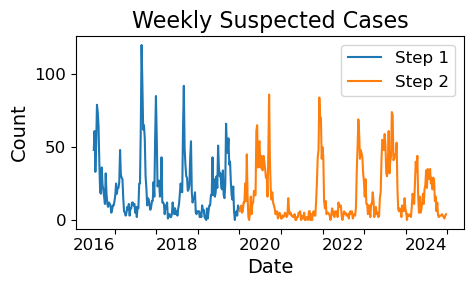

In [23]:
years = mdates.YearLocator(base = 1)
months = mdates.YearLocator(base = 2, month=7) 
yearsFmt = mdates.DateFormatter('\n%Y')

fig, ax = plt.subplots(figsize=(5, 2.5))
ax.plot(y_train.index, y_train, label="Step 1")
ax.plot(y_test.index, y_test, label="Step 2")
ax.legend(fontsize=12)
ax.set_title("Dataset Splits", fontsize=16)
ax.tick_params(labelsize = 12)
ax.set_title("Weekly Suspected Cases", fontsize = 16)
ax.set_xlabel("Date", fontsize = 14)
ax.set_ylabel("Count", fontsize = 14)
# Set the major locator to YearLocator
ax.xaxis.set_major_locator(years)

# Set the major formatter to NullFormatter
ax.xaxis.set_major_formatter(ticker.NullFormatter())

# Set the minor locator to MonthLocator
ax.xaxis.set_minor_locator(months)

# Set the minor formatter to display the year
yearsFmt = mdates.DateFormatter('\n%Y')
ax.xaxis.set_minor_formatter(yearsFmt)

# Align the minor tick labels to center
for label in ax.get_xticklabels(minor=True):
    label.set_horizontalalignment('center')
    label.set_verticalalignment('center')
ax.set_xlabel("Date", fontsize = 14)
ax.tick_params(which = "both", labelsize = 12)
ax.tick_params(which = "minor", bottom = False)
fig.align_ylabels()
plt.savefig(img_dir / "train_test_split.png", dpi = 300, bbox_inches = "tight")

## Data Preprocessing

In [24]:
max_abs_scaler = MaxAbsScaler()
X_train_scaled = max_abs_scaler.fit_transform(X_train)
X_test_scaled = max_abs_scaler.transform(X_test)

df_train = (
    pd.DataFrame(
        X_train_scaled, 
        columns = X_train.columns,
        index = X_train.index
    )
    .assign(
        y = y_train.values,
    )
    .reset_index()
)
df_test = (
    pd.DataFrame(
        X_test_scaled, 
        columns = X_test.columns,
        index = X_test.index
    )
    .assign(
        y = y_test.values,
    )
    .reset_index()
)

## Simple Correlation Analysis

In [25]:
corr_factors = (
    df_train
    .drop(columns = ["ds"])
    .corr()
    ["y"]
    .T
    .to_frame(name = "corr")
    .loc[lambda x: x.index != "y"]
    .loc[lambda x: x["corr"] >= 0.01]
    .sort_values(by = "corr", ascending = False, key = np.abs)
)

#### Extract features with low correlation

In [26]:
list_of_relevant_features_simple = [corr_factors.index.tolist()[0]]
for f in corr_factors.index.tolist()[1:]:
    corrs = df_train[list_of_relevant_features_simple + [f]].corr()[f].abs()
    if corrs[:-1].max() < 0.5:
        list_of_relevant_features_simple.append(f)    

In [27]:
len(list_of_relevant_features_simple)

38

In [28]:
corr_factors

,corr
week,0.433025
esi_1w,0.411691
esi__abs_energy,0.402848
esi_2w,0.391017
esi_mean_4w,0.372914
esi_3w,0.306792
rainfall_mm__index_mass_quantile__q_0.1,0.274637
esi_mean_8w,0.253555
esi_4w,0.219935
num_fatalities__has_duplicate_max,0.194551


#### Final Dataset

In [29]:
df_reports_cov_corr_simple = (
    df_test
    .reset_index()
    [["ds", "y"] + list_of_relevant_features_simple]
    .assign(
        **{
            f"{feat}_corr": lambda x, feat=feat: x[feat] * corr_factors.loc[lambda x: x.index == feat, "corr"].values[0]
            for feat in list_of_relevant_features_simple
        }
    )
    .assign(
        cov = lambda x: np.exp(normalize(
            x
            [[c for c in x.columns if c.endswith("_corr")]]
            .sum(axis = 1)
        )),
        # y = lambda x: np.exp(x["y"]) - 1,
    )
    .merge(
        df_weekly[["ds", "rdt_confirmed", "idps", "num_disaster_affected", "covid_cases_per_million", "covid_deaths_per_million", "vacc", "vacc_prop"]],
        on = "ds",
        how = "left"
    )
    .rename(
        columns = {
            "ds": "date",
            "y": "reports"
        }
    )
    [["date", "reports", "idps", "num_disaster_affected", "vacc", "covid_cases_per_million", "covid_deaths_per_million", "cov"]]
)
    

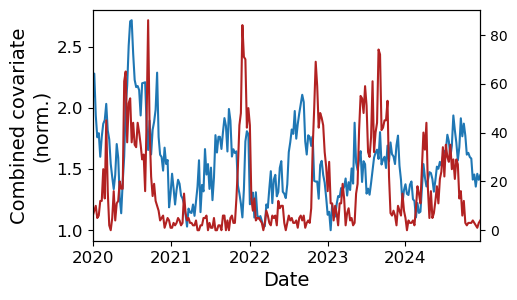

In [30]:
fig, ax = plt.subplots(figsize=(5, 3))
(
    df_reports_cov_corr_simple
    .set_index("date")
    .plot(
        y = "cov",
        ax = ax, 
        legend = False
    )
)
ax2 = ax.twinx()
(
    df_reports_cov_corr_simple
    .set_index("date")
    .plot(
        y = "reports",
        ax = ax2, 
        legend = False,
        color = "firebrick"
    )
)
ax.set_ylabel("Combined covariate\n(norm.)", fontsize = 14)
ax.set(xticks=["2020-01-01", "2021-01-01", "2022-01-01", "2023-01-01", "2024-01-01"])
ax.set_xticklabels(["2020", "2021", "2022", "2023", "2024"], fontsize = 12) 
ax.set_xlabel("Date", fontsize = 14)
ax.tick_params(axis = "y", labelsize = 12)
plt.minorticks_off()
plt.savefig(img_dir / "combined_covariates.png", dpi = 300, bbox_inches = "tight")

## ML Models on Train Data

In [31]:
custom_scorer = make_scorer(
    custom_smape,
    greater_is_better = False,
)

log_transformer = FunctionTransformer(
    func = np.log1p,
    inverse_func = np.expm1,
)

scoring = {
    "neg_max_error": make_scorer(max_error, greater_is_better=False),
    "high_count_precision": make_scorer(high_count_metric, threshold = 25, greater_is_better=False),
}

### Lasso

#### Hyperparameter Search

In [32]:
# lasso_pipe = Pipeline([
#     ("lasso", TransformedTargetRegressor(regressor = Lasso(), transformer = log_transformer)),
# ])

# lasso_search = dict(
#     lasso__regressor__alpha = Real(0.001, 1000, "log-uniform"),
#     lasso__regressor__max_iter = Integer(2000, 30000),
#     lasso__regressor__tol = Real(1e-7, 1e-4, "log-uniform"),
# )

lasso_search = dict(
    alpha = Real(0.001, 1000, "log-uniform"),
    # max_iter = Integer(10, 3000),
    # tol = Real(1e-9, 1e-1, "log-uniform"),
)

# lasso_opt = BayesSearchCV(
#     lasso_pipe,
#     search_spaces = lasso_search,
#     random_state = seed,
#     scoring = "neg_max_error",
#     n_iter = 30,
#     n_jobs = -1,
#     return_train_score = True
# )
lasso_opt = BayesSearchCV(
    estimator = Lasso(max_iter = 1000, tol = 0.01),
    search_spaces = lasso_search,
    random_state = seed,
    # scoring = "neg_max_error",
    scoring = scoring,
    refit = "neg_max_error",
    n_iter = 30,
    n_jobs = -1,
    return_train_score = True
)

In [33]:
lasso_opt.fit(X_train_scaled, y_train)

/Users/paoich/miniforge3/envs/cholera-surveillance/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.352e+03, tolerance: 6.433e+02
  model = cd_fast.enet_coordinate_descent(
/Users/paoich/miniforge3/envs/cholera-surveillance/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.416e+03, tolerance: 6.752e+02
  model = cd_fast.enet_coordinate_descent(
/Users/paoich/miniforge3/envs/cholera-surveillance/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iter

BayesSearchCV(estimator=Lasso(tol=0.01), n_iter=30, n_jobs=-1,
              random_state=4183, refit='neg_max_error', return_train_score=True,
              scoring={'high_count_precision': make_scorer(high_count_metric, greater_is_better=False, response_method='predict', threshold=25),
                       'neg_max_error': make_scorer(max_error, greater_is_better=False, response_method='predict')},
              search_spaces={'alpha': Real(low=0.001, high=1000, prior='log-uniform', transform='normalize')})

In [34]:
lasso_opt.best_params_

OrderedDict([('alpha', 0.2158240013201912)])

In [35]:
lasso_opt.best_score_

-48.65985870361328

<Axes: title={'center': 'Convergence plot'}, xlabel='Number of calls $n$', ylabel='$\\min f(x)$ after $n$ calls'>

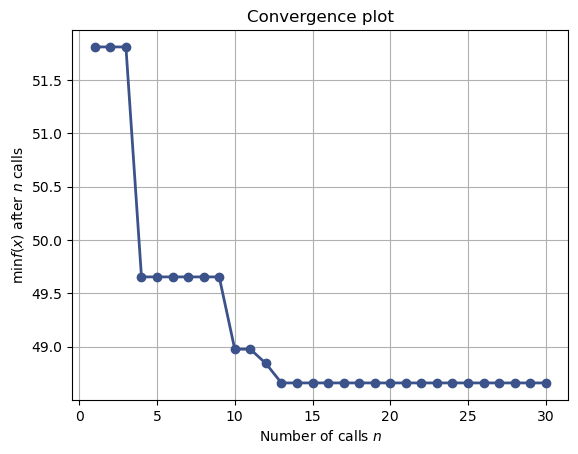

In [36]:
plot_convergence(lasso_opt.optimizer_results_[0])

<Axes: >

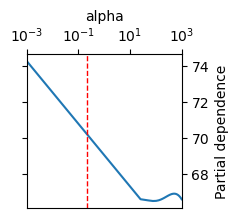

In [37]:
plot_objective(
    lasso_opt.optimizer_results_[0],
    dimensions = ["alpha"],
    n_minimum_search=int(1e8)
)

#### Predictions

In [38]:
lasso_best = lasso_opt.best_estimator_

##### Predict on train set

In [39]:
lasso_best_pred_train = lasso_best.predict(X_train_scaled)

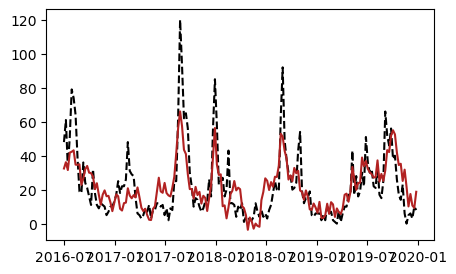

In [40]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(
    y_train.index,
    y_train,
    label = "Data",
    color = "black",
    linestyle = "--"
)
ax.plot(
    y_train.index,
    lasso_best_pred_train,
    label = "Validation",
    color = "firebrick"
)

##### Predict on test set

In [112]:
lasso_best = lasso_opt.best_estimator_
lasso_best_pred_test = (
    lasso_best.predict(X_test_scaled)
    # .clip(min = 0)
)

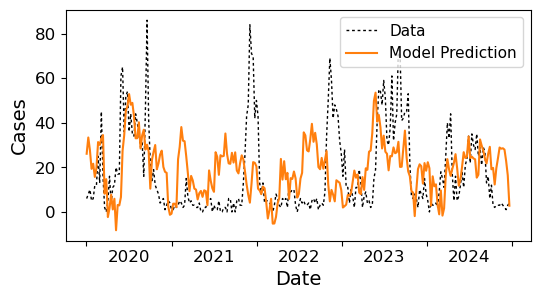

In [113]:
dates_true = y_test.index
chol_true = y_test
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(
    y_test.index,
    y_test,
    color = "black",
    linewidth = 1,
    dashes = [2, 2],
    label = "Data"
)
ax.plot(
    y_test.index,
    lasso_best_pred_test,
    color = "C1",
    linewidth = 1.5,
    label = "Model Prediction"
)
ax.tick_params(labelsize = 12)
ax.set_ylabel("Cases", fontsize = 14)
# Set the major locator to YearLocator
years = mdates.YearLocator()
ax.xaxis.set_major_locator(years)

# Set the major formatter to NullFormatter
ax.xaxis.set_major_formatter(ticker.NullFormatter())

# Set the minor locator to MonthLocator
months = mdates.MonthLocator(bymonth=(7))  # January and July for example
ax.xaxis.set_minor_locator(months)

# Set the minor formatter to display the year
yearsFmt = mdates.DateFormatter('\n%Y')
ax.xaxis.set_minor_formatter(yearsFmt)

# Align the minor tick labels to center
for label in ax.get_xticklabels(minor=True):
    label.set_horizontalalignment('center')
    label.set_verticalalignment('center')
ax.set_xlabel("Date", fontsize = 14)
ax.tick_params(which = "both", labelsize = 12)
ax.tick_params(which = "minor", bottom = False)

ax.legend(
    # bbox_to_anchor=(1, 1),
    fontsize = 11
)
ax.set_xlabel("Date", fontsize = 14)
plt.savefig(img_dir / "xgb_best_pred_test.png", dpi = 300, bbox_inches = "tight")

#### Extract Model coefficients

In [43]:
df_lasso_coef = (
    pd.DataFrame(
        # lasso_best["lasso"].regressor_.coef_,
        lasso_best.coef_,
        index = X_train.columns,
        columns = ["coef"]
    )
    .loc[lambda x: np.abs(x["coef"]) > 0]
    .sort_values(by = "coef", ascending = False, key = np.abs)
)

In [44]:
df_lasso_coef.shape

(22, 1)

In [105]:
df_lasso_coef.head().round(3)

,coef
rainfall_mm_sum_8w,-29.806000
esi__abs_energy,25.948999
rainfall_mm__count_above_mean,13.157000
lake_level__fourier_entropy__bins_3,-10.286000
spei__mean_change,-8.087000


In [106]:
(
    df_lasso_coef
    .assign(
        coef = lambda x: x["coef"].astype(float).round(2)
    )
    # .reset_index()
    # .rename(
    #     columns = {
    #         "index": "Feature",
    #         "coef": "Coefficient"
    #     }
    # )
)

,coef
rainfall_mm_sum_8w,-29.81
esi__abs_energy,25.95
rainfall_mm__count_above_mean,13.16
lake_level__fourier_entropy__bins_3,-10.29
spei__mean_change,-8.09
esi__variance_larger_than_standard_deviation,7.99
lake_level__mean_abs_change,-7.55
esi_1w,7.53
rainfall_mm_sum_4w,-7.52
spei__index_mass_quantile__q_0.1,-6.77


In [110]:
cm = sns.diverging_palette(10, 162, as_cmap=True)
lasso_coef_table = (
    df_lasso_coef
    .assign(
        coef = lambda x: x["coef"].astype(float).round(2)
    )
    .reset_index()
    .rename(
        columns = {
            "index": "Feature",
            "coef": "Coefficient"
        }
    )
    .style
    .format({"Coefficient": "{:.2f}"})
    .background_gradient(cmap=cm)
    .set_properties(**{"font-size": "14pt"})
    # .set_table_attributes('style="width: 50%; margin: auto;"')
    .set_caption("Lasso Model")
    .set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("font-size", "20pt"), 
                    ("text-align", "center"),
                    ("font-weight", "bold"),
                ],
            },
            {
                "selector": "th",
                "props": [("font-size", "14pt"), ("text-align", "center")],
            },
            {
                "selector": "td",
                "props": [("font-size", "14pt"), ("text-align", "right")],
            },
        ]
    )
    .hide(axis="index")
)
lasso_coef_table

Feature,Coefficient
rainfall_mm_sum_8w,-29.81
esi__abs_energy,25.95
rainfall_mm__count_above_mean,13.16
lake_level__fourier_entropy__bins_3,-10.29
spei__mean_change,-8.09
esi__variance_larger_than_standard_deviation,7.99
lake_level__mean_abs_change,-7.55
esi_1w,7.53
rainfall_mm_sum_4w,-7.52
spei__index_mass_quantile__q_0.1,-6.77


In [111]:
imgkit.from_string(
    lasso_coef_table.to_html(),
    img_dir / "lasso_coef_table.png"
)

Loading page (1/2)
Rendering (2/2)                                                    
Done                                                               


True

#### Final Dataset

In [47]:
df_reports_cov_lasso = (
    df_test
    [["ds", "y"] + df_lasso_coef.index.tolist()]
    # .assign(
    #     **{f"{feat}_lasso": lambda x, feat=feat: (
    #             x[feat] 
    #             * df_lasso_coef.loc[lambda x: x.index == feat, "coef"].values[0]
    #         )
    #         for feat in df_lasso_coef.index.tolist()
    #     }
    # )
    # .assign(
    #     cov = lambda x: (
    #         # np.expm1(
    #         #     # lasso_best["lasso"].regressor_.intercept_ + 
    #         #     lasso_best.intercept_ +
    #         #     x[[c for c in x.columns if c.endswith("_lasso")]].sum(axis = 1)
    #         # )
    #         (
    #             # lasso_best["lasso"].regressor_.intercept_ + 
    #             lasso_best.intercept_ +
    #             x[[c for c in x.columns if c.endswith("_lasso")]].sum(axis = 1)
    #         )
    #     )
    # )
    .assign(
        # cov = normalize(lasso_best_pred_test)
        cov = lasso_best_pred_test
    )
    .merge(
        # df_weekly[["ds", "rdt_confirmed", "idps", "num_disaster_affected", "vacc_1", "vacc_1_prop", "vacc_2", "vacc_2_prop"]],
        df_weekly[["ds", "rdt_confirmed", "idps", "num_disaster_affected", "covid_cases_per_million", "covid_deaths_per_million", "vacc", "vacc_prop"]],
        on = "ds",
        how = "left"
    )
    .rename(
        columns = {
            "ds": "date",
            "y": "reports"
        }
    )
    # [["date", "reports", "rdt_confirmed", "idps", "num_disaster_affected", "vacc_1", "vacc_1_prop", "vacc_2", "vacc_2_prop", "cov"] + df_lasso_coef.index.tolist()]
    [[
        "date", 
        "reports", 
        "rdt_confirmed", 
        "idps", 
        "num_disaster_affected",
        "covid_cases_per_million",
        "covid_deaths_per_million",
        "vacc",
        "vacc_prop",
        "cov"
    ] + df_lasso_coef.index.tolist()]
)

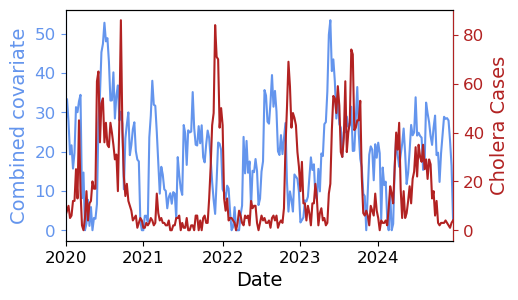

In [48]:
fig, ax = plt.subplots(figsize=(5, 3))
(
    df_reports_cov_lasso
    .set_index("date")
    .plot(
        y = "cov",
        ax = ax, 
        color = "cornflowerblue",
        legend = False
    )
)
ax2 = ax.twinx()
(
    df_reports_cov_lasso
    .set_index("date")
    .plot(
        y = "reports",
        ax = ax2, 
        legend = False,
        color = "firebrick"
    )
)
ax.set_ylabel("Combined covariate", fontsize = 14, color = "cornflowerblue")
ax.set(xticks=["2020-01-01", "2021-01-01", "2022-01-01", "2023-01-01", "2024-01-01"])
ax.set_xticklabels(["2020", "2021", "2022", "2023", "2024"], fontsize = 12) 
ax.set_xlabel("Date", fontsize = 14)
ax.spines["left"].set_color("cornflowerblue")
ax.tick_params(axis = "y", color = "cornflowerblue", labelsize = 12, labelcolor = "cornflowerblue")
ax2.set_ylabel("Cholera Cases", fontsize = 14, color = "firebrick")
ax2.spines["right"].set_color("firebrick")
ax2.tick_params(axis = "y", color = "firebrick", labelsize = 12, labelcolor = "firebrick")
plt.minorticks_off()
# ax.set_ylim(df_reports_cov_lasso["reports"].min(), df_reports_cov_lasso["reports"].max())
plt.savefig(img_dir / "combined_covariates_and_cholera.png", dpi = 300, bbox_inches = "tight")

### XGBoost

#### Hyperparameter Search

In [49]:
xgb_pipe = Pipeline([
    (
        "xgb", 
        TransformedTargetRegressor(
            regressor = xgb.XGBRegressor(
                booster = "gblinear",
                objective = "reg:squarederror",
                random_state = seed
            ), 
            transformer = log_transformer
        )
    ),
])

# xgb_search = {
#     "learning_rate": Real(1e-5, 0.1, "log-uniform"),
#     "n_estimators": Integer(10, 5000),
#     # "max_depth": Integer(3, 10),
#     "alpha": Real(0.001, 1000, "log-uniform"),
#     # "objective": Categorical(["reg:squarederror", "reg:absoluteerror"]),
#     # "eval_metric": (["rmse", "mae", "rmsle", "mape", "logloss", "poisson-nloglik", "gamma-nloglik"]),
# }
# xgb_search = {
#     "xgb__regressor__learning_rate": Real(1e-5, 0.1, "log-uniform"),
#     "xgb__regressor__n_estimators": Integer(10, 1000),
#     # "max_depth": Integer(3, 10),
#     "xgb__regressor__alpha": Real(0.01, 1000, "log-uniform"),
#     # "xgb__regressor__objective": Categorical(["reg:squarederror", "reg:absoluteerror"]),
#     # "xgb__regressor__eval_metric": (["rmse", "mae", "rmsle", "mape", "logloss", "poisson-nloglik", "gamma-nloglik"]),
# }
# xgb_search = dict(
#     xgb__regressor__learning_rate=lognorm(scale=np.exp(0.1), s = 1),
#     xgb__regressor__n_estimators=randint(10, 1000),
#     xgb__regressor__alpha=lognorm(scale=np.exp(0.3), s = 5)
# )
xgb_search = dict(
    learning_rate=np.logspace(-5, -1, 20),
    n_estimators=np.arange(100, 500, 20),
    alpha=np.logspace(-2, 1, 20),
)
# xgb_search = dict(
#     xgb__regressor__learning_rate=np.logspace(-5, -1, 10),
#     xgb__regressor__n_estimators=np.arange(100, 500, 50),
#     xgb__regressor__alpha=np.logspace(-2, 1, 10),
#     # xgb__regressor__reg_lambda=np.logspace(-2, 2, 10),
#     # min_split_loss=np.arange(1, 10, 2),
#     # max_depth=np.arange(3, 10, 1)
# )

# xgb_opt = BayesSearchCV(
# xgb_opt = RandomizedSearchCV(
#     # estimator = xgb_pipe,
#     estimator = xgb.XGBRegressor(
#         booster = "gblinear",
#         objective = "reg:squarederror",
#         eval_metric = custom_scorer,
#         random_state = seed
#     ),
#     param_distributions = xgb_search,
#     random_state = seed,
#     # scoring = custom_scorer,
#     n_iter = 30,
#     n_jobs = -1,
#     cv = 3,
#     return_train_score = True
# )
xgb_opt = GridSearchCV(
    # estimator = xgb_pipe,
    estimator = xgb.XGBRegressor(
        booster = "gblinear",
        objective = "reg:squarederror",
        # eval_metric = custom_scorer,
        random_state = seed
    ),
    param_grid = xgb_search,
    scoring = "neg_max_error",
    n_jobs = -1,
    cv = 3,
    return_train_score = True
)

In [50]:
xgb_opt.fit(X_train_scaled, y_train.values)

GridSearchCV(cv=3,
             estimator=XGBRegressor(base_score=None, booster='gblinear',
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping_rounds=None,
                                    enable_categorical=False, eval_metric=None,
                                    feature_types=None, gamma=None,
                                    grow_policy=None, importance_type=None,
                                    interaction_constraints=None,
                                    learning_rate=...
       6.95192796e-05, 1.12883789e-04, 1.83298071e-04, 2.97635144e-04,
       4.83293024e-04, 7.84759970e-04, 1.27427499e-03, 2.06913808e-03,
       3.35981829e-03, 5.45559478e-03, 8.85866790e-03, 1.43844989e-02,
       2.33572147e-02, 3.79269019e-02, 6.15848211e-02, 1.00000000e-01]),
                         'n_estimators': array([100, 120, 140, 160, 180, 200, 220, 240, 260, 280, 300, 320, 340,
       360, 380, 400, 420, 440, 460, 480])},
             return_train_score=True, scoring='neg_max_error')

In [51]:
xgb_opt.best_score_

-49.120070457458496

In [52]:
xgb_opt.best_params_

{'alpha': 0.08858667904100823, 'learning_rate': 0.1, 'n_estimators': 180}

#### Predictions

In [53]:
xgb_best = xgb_opt.best_estimator_

##### Predictions on train set

In [54]:
xgb_best_pred_train = xgb_best.predict(X_train_scaled)

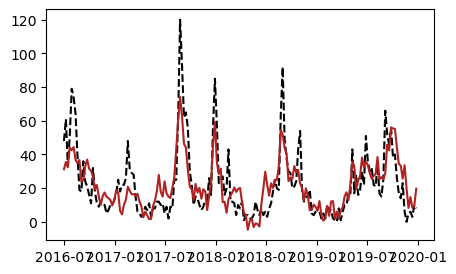

In [55]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(
    y_train.index,
    y_train,
    label = "Data",
    color = "black",
    linestyle = "--"
)
ax.plot(
    y_train.index,
    xgb_best_pred_train,
    label = "Validation",
    color = "firebrick"
)

##### Predict on test set

In [122]:
xgb_best_pred_test = (
    xgb_best.predict(X_test_scaled)
    # .clip(min = 0)
)

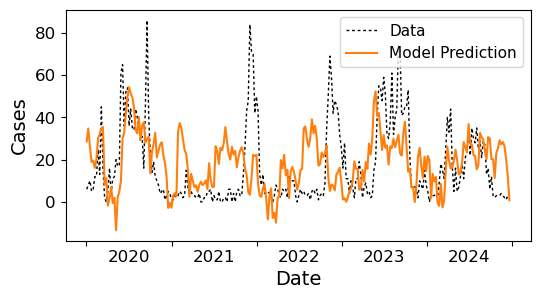

In [123]:
dates_true = y_test.index
chol_true = y_test
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(
    y_test.index,
    y_test,
    color = "black",
    linewidth = 1,
    dashes = [2, 2],
    label = "Data"
)
ax.plot(
    y_test.index,
    xgb_best_pred_test,
    color = "C1",
    linewidth = 1.5,
    label = "Model Prediction"
)
ax.tick_params(labelsize = 12)
ax.set_ylabel("Cases", fontsize = 14)
# Set the major locator to YearLocator
years = mdates.YearLocator()
ax.xaxis.set_major_locator(years)

# Set the major formatter to NullFormatter
ax.xaxis.set_major_formatter(ticker.NullFormatter())

# Set the minor locator to MonthLocator
months = mdates.MonthLocator(bymonth=(7))  # January and July for example
ax.xaxis.set_minor_locator(months)

# Set the minor formatter to display the year
yearsFmt = mdates.DateFormatter('\n%Y')
ax.xaxis.set_minor_formatter(yearsFmt)

# Align the minor tick labels to center
for label in ax.get_xticklabels(minor=True):
    label.set_horizontalalignment('center')
    label.set_verticalalignment('center')
ax.set_xlabel("Date", fontsize = 14)
ax.tick_params(which = "both", labelsize = 12)
ax.tick_params(which = "minor", bottom = False)

ax.legend(
    # bbox_to_anchor=(1, 1),
    fontsize = 11
)
ax.set_xlabel("Date", fontsize = 14)
plt.savefig(img_dir / "xgb_best_pred_test.png", dpi = 300, bbox_inches = "tight")

#### Extract Model coefficients

In [124]:
df_xgb_coef = (
    pd.DataFrame(
        # np.c_[X_train.columns, xgb_best["xgb"].regressor_.coef_],
        np.c_[X_train.columns, xgb_best.coef_],
        columns = ["feature", "coef"]
    )
    .loc[lambda x: np.abs(x["coef"]) > 0]
    .sort_values(by = "coef", ascending = False, key = np.abs)
)

In [125]:
df_xgb_coef.shape

(116, 2)

In [126]:
xgb_relevant_features = [df_xgb_coef["feature"].values.tolist()[0]]
for f in df_xgb_coef["feature"].values.tolist()[1:]:
    corrs = df_train[xgb_relevant_features + [f]].corr()[f].abs()
    if corrs[:-1].max() < 0.5:
        xgb_relevant_features.append(f)   

In [127]:
len(xgb_relevant_features)

76

<Axes: >

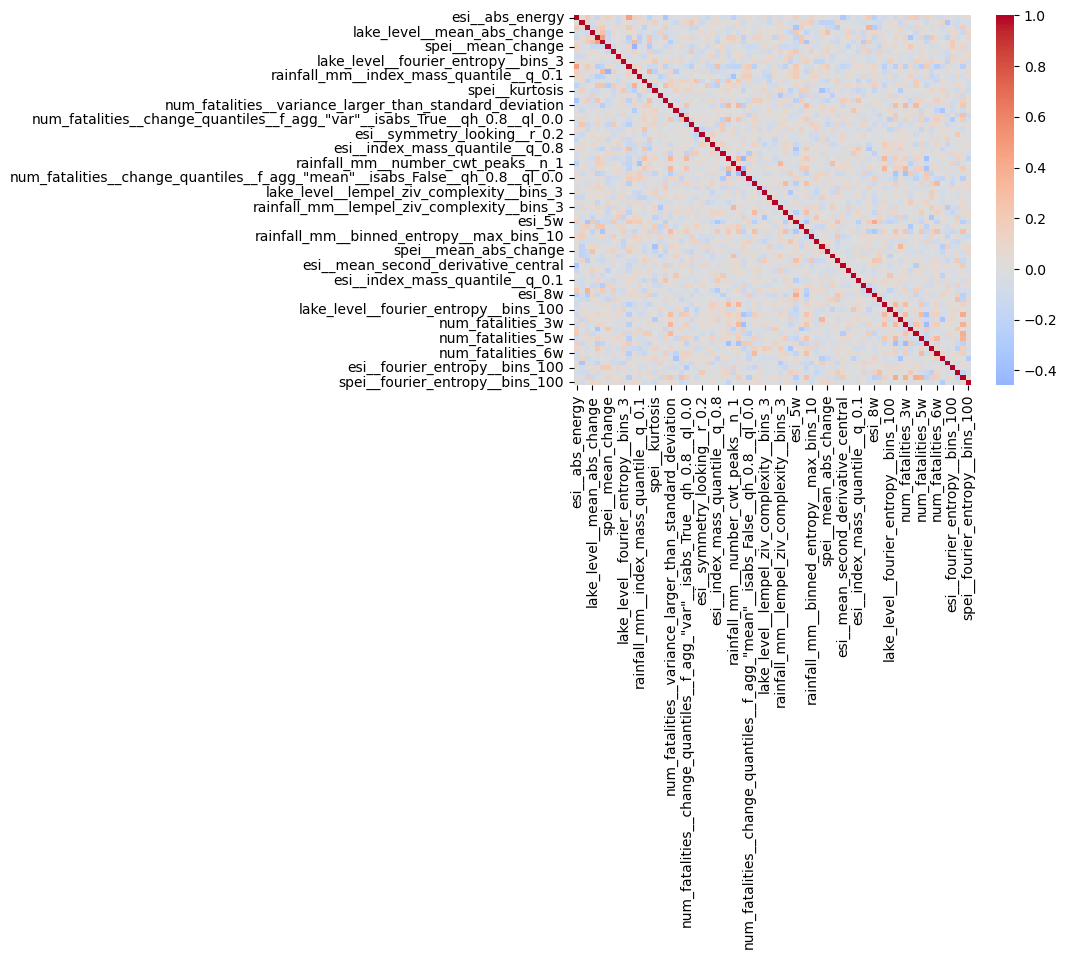

In [128]:
sns.heatmap(
    df_train
    [xgb_relevant_features]
    .corr(),
    center = 0,
    cmap = "coolwarm",
)

#### Final Dataset

In [129]:
df_reports_cov_xgb = (
    df_test
    [["ds", "y"] + df_xgb_coef["feature"].tolist()]
    # .assign(
    #     **{
    #         f"{feat}_xgb": lambda x, feat=feat: x[feat] * df_xgb_coef.loc[lambda x: x["feature"] == feat, "coef"].values[0]
    #         for feat in df_xgb_coef["feature"].tolist()
    #     }
    # )
    # .assign(
    #     cov = lambda x: normalize(
    #         xgb_best.intercept_ +
    #         # xgb_best["xgb"].regressor_.intercept_ + 
    #         x[[c for c in x.columns if c.endswith("_xgb")]].sum(axis = 1)
    #     )
    # )
    .assign(
        # cov = normalize(xgb_best_pred_test)
        cov = xgb_best_pred_test
    )
    .merge(
        df_weekly[["ds", "rdt_confirmed", "idps", "num_disaster_affected", "covid_cases_per_million", "covid_deaths_per_million", "vacc", "vacc_prop"]],
        on = "ds",
        how = "left"
    )
    .rename(
        columns = {
            "ds": "date",
            "y": "reports"
        }
    )
    [
        [
            "date", 
            "reports", 
            "rdt_confirmed", 
            "idps", 
            "num_disaster_affected", 
            "covid_cases_per_million",
            "covid_deaths_per_million",
            "vacc",
            "vacc_prop",
            "cov"
        ] + df_xgb_coef["feature"].tolist()
    ]
)

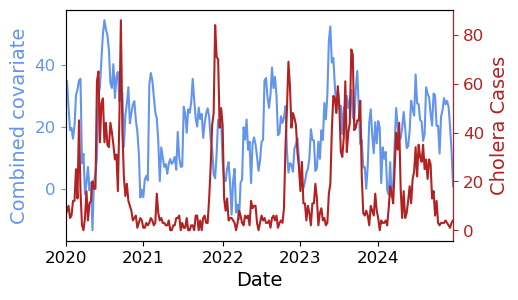

In [130]:
fig, ax = plt.subplots(figsize=(5, 3))
(
    df_reports_cov_xgb
    .set_index("date")
    .plot(
        y = "cov",
        ax = ax, 
        color = "cornflowerblue",
        legend = False
    )
)
ax2 = ax.twinx()
(
    df_reports_cov_xgb
    .set_index("date")
    .plot(
        y = "reports",
        ax = ax2, 
        legend = False,
        color = "firebrick"
    )
)
ax.set_ylabel("Combined covariate", fontsize = 14, color = "cornflowerblue")
ax.set(xticks=["2020-01-01", "2021-01-01", "2022-01-01", "2023-01-01", "2024-01-01"])
ax.set_xticklabels(["2020", "2021", "2022", "2023", "2024"], fontsize = 12) 
ax.set_xlabel("Date", fontsize = 14)
ax.spines["left"].set_color("cornflowerblue")
ax.tick_params(axis = "y", color = "cornflowerblue", labelsize = 12, labelcolor = "cornflowerblue")
ax2.set_ylabel("Cholera Cases", fontsize = 14, color = "firebrick")
ax2.spines["right"].set_color("firebrick")
ax2.tick_params(axis = "y", color = "firebrick", labelsize = 12, labelcolor = "firebrick")
plt.minorticks_off()
plt.savefig(img_dir / "combined_covariates_and_cholera.png", dpi = 300, bbox_inches = "tight")

### Best non-interpretable model

#### Hyperparameter Search

In [65]:
xgbtree_pipe = Pipeline([
    (
        "xgb", 
        TransformedTargetRegressor(
            regressor = xgb.XGBRegressor(
                objective = "reg:squarederror",
                min_split_loss = 1,
                n_estimators = 200,
                #  learning_rate = 0.19,
                #  alpha = 2,
                #  reg_lambda = 11,
                max_depth = 2,
                random_state = seed

            ), 
            transformer = log_transformer
        )
    ),
])
# xgbtree_search = dict(
#     # xgb__regressor__learning_rate=np.logspace(-5, -1, 5),
#     xgbtree_pipe__regressor__learning_rate=np.linspace(0.15, 0.25, 10),
#     # xgb__regressor__n_estimators=np.arange(100, 500, 100),
#     # xgb__regressor__alpha=np.logspace(-2, 1, 5),
#     xgb__regressor__alpha=np.linspace(1, 3, 10),
#     # xgb__regressor__reg_lambda=np.logspace(-2, 2, 5),
#     xgb__regressor__reg_lambda=np.linspace(5, 20, 10),
#     # xgb__regressor__min_split_loss=np.arange(1, 5, 2),
#     # xgb__regressor__max_depth=np.arange(3, 5, 1)
# )

xgbtree_search = dict(
    learning_rate=np.logspace(-1, 1, 10),
    # learning_rate = np.linspace(1e-2, 0.2, 10),
    alpha=np.logspace(-2, 1, 10),
    # alpha = np.linspace(1e-1, 10, 10),
    reg_lambda=np.logspace(0, 2, 10),
    # reg_lambda = np.linspace(5, 500, 10),
    # min_split_loss=np.arange(1, 5, 2),
    # max_depth=np.arange(1, 10, 2)
)

xgbtree_best = GridSearchCV(
    #estimator = xgbtree_pipe,
    estimator = xgb.XGBRegressor(
         # eval_metric = custom_scorer,
         min_split_loss = 3,
         n_estimators = 300,
        #  learning_rate = 0.1,
        #  alpha = 2,
        #  reg_lambda = 11,
         max_depth = 1,
         random_state = seed
    ),
    param_grid = xgbtree_search,
    scoring = "neg_max_error",
    n_jobs = -1,
    cv = 3,
    return_train_score = True
)

In [66]:
xgbtree_best.fit(X_train_scaled, y_train.values)

/Users/paoich/miniforge3/envs/cholera-surveillance/lib/python3.12/site-packages/sklearn/model_selection/_validation.py:960: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/Users/paoich/miniforge3/envs/cholera-surveillance/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 949, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/paoich/miniforge3/envs/cholera-surveillance/lib/python3.12/site-packages/sklearn/metrics/_scorer.py", line 288, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **_kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/paoich/miniforge3/envs/cholera-surveillance/lib/python3.12/site-packages/sklearn/metrics/_scorer.py", line 388, in _score
 

GridSearchCV(cv=3,
             estimator=XGBRegressor(base_score=None, booster=None,
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping_rounds=None,
                                    enable_categorical=False, eval_metric=None,
                                    feature_types=None, gamma=None,
                                    grow_policy=None, importance_type=None,
                                    interaction_constraints=None,
                                    learning_rate=None, m...
             param_grid={'alpha': array([ 0.01      ,  0.02154435,  0.04641589,  0.1       ,  0.21544347,
        0.46415888,  1.        ,  2.15443469,  4.64158883, 10.        ]),
                         'learning_rate': array([ 0.1       ,  0.16681005,  0.27825594,  0.46415888,  0.77426368,
        1.29154967,  2.15443469,  3.59381366,  5.9948425 , 10.        ]),
                         'reg_lambda': array([  1.        ,   1.66810054,   2.7825594 ,   4.64158883,
         7.74263683,  12.91549665,  21.5443469 ,  35.93813664,
        59.94842503, 100.        ])},
             return_train_score=True, scoring='neg_max_error')

In [67]:
xgbtree_best.best_score_

-49.40168682734171

In [68]:
xgbtree_best.best_params_

{'alpha': 10.0,
 'learning_rate': 0.774263682681127,
 'reg_lambda': 1.6681005372000588}

#### Predictions

In [69]:
xgbtree_best = xgbtree_best.best_estimator_

##### Predictions on train set

In [70]:
xgbtree_best_pred_train = xgbtree_best.predict(X_train_scaled)

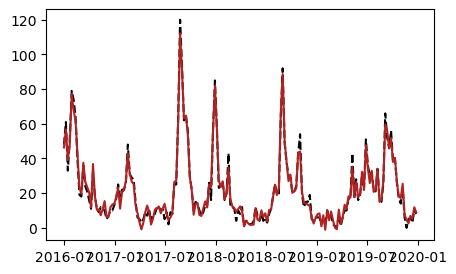

In [71]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(
    y_train.index,
    y_train,
    label = "Data",
    color = "black",
    linestyle = "--"
)
ax.plot(
    y_train.index,
    xgbtree_best_pred_train,
    label = "Validation",
    color = "firebrick"
)

##### Predict on test set

In [72]:
xgbtree_best_pred_test = (
    xgbtree_best.predict(X_test_scaled)
    .clip(min = 0)
)

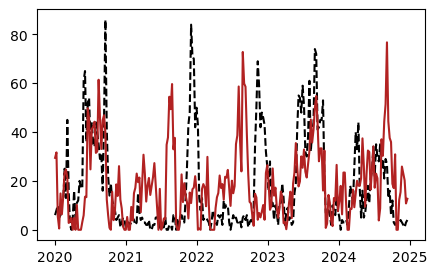

In [73]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(
    y_test.index,
    y_test,
    label = "Data",
    color = "black",
    linestyle = "--"
)
ax.plot(
    y_test.index,
    xgbtree_best_pred_test,
    label = "Validation",
    color = "firebrick"
)

#### SHAP coefficients

In [74]:
xgbtree_explainer = shap.Explainer(xgbtree_best)

In [75]:
xgb_shap = xgbtree_explainer(df_test.drop(columns = ["ds", "y"]))

In [76]:
df_xgbtree_shap = (
    pd.DataFrame(
        data = xgb_shap.values,
        columns = xgb_shap.feature_names,
    )
)

Text(0.5, 1.0, 'Gradient Boosting Regressor SHAP Values')

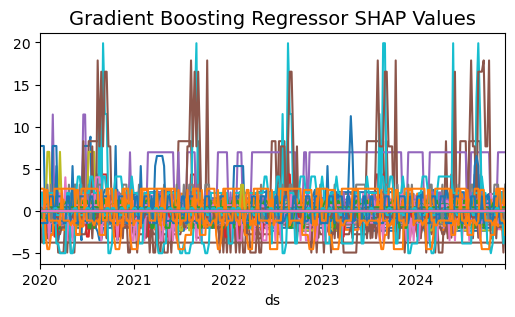

In [77]:
fig, ax = plt.subplots(figsize=(6, 3))
(
    pd.concat([df_test["ds"], df_xgbtree_shap], axis = 1)
    .set_index("ds")
    .plot(legend=False, ax=ax)
)
ax.set_title("Gradient Boosting Regressor SHAP Values", fontsize = 14)

#### Final Dataset

In [78]:
df_shap_importance = (
    df_xgbtree_shap
    .abs()
    .sum()
    .sort_values(ascending = False)
)

In [79]:
df_train[["rainfall_mm_8w", "rainfall_mm_sum_8w"]].corr()

,rainfall_mm_8w,rainfall_mm_sum_8w
rainfall_mm_8w,1.000000,0.729344
rainfall_mm_sum_8w,0.729344,1.000000


In [80]:
list_of_relevant_features_xgbrtree = [df_shap_importance.index.values.tolist()[0]]
for f in df_shap_importance.index.values.tolist()[1:]:
    corrs = df_train[list_of_relevant_features_xgbrtree + [f]].corr()[f].abs()
    if corrs[:-1].max() < 0.5:
        list_of_relevant_features_xgbrtree.append(f)    

In [81]:
important_features = (
    df_shap_importance
    # [list_of_relevant_features_xgbrtree]
    .head(7)
    .index
    .tolist()
)

df_reports_cov_xgbtree = (
    pd.concat([df_test[["ds"]], df_xgbtree_shap], axis = 1)
    .set_index("ds")
    # .assign(
    #     cov = lambda x: (
    #         x.sum(axis = 1)
    #     )
    # )
    .assign(
        # cov = normalize(xgbtree_best_pred_test)
        cov = xgbtree_best_pred_test
    )
    .reset_index()
    .merge(
        df_weekly[["ds", "y", "rdt_confirmed", "idps", "num_disaster_affected", "covid_cases_per_million", "covid_deaths_per_million", "vacc", "vacc_prop"]],
        on = "ds",
        how = "left"
    )
    .rename(
        columns = {
            "ds": "date",
            "y": "reports"
        }
    )
    [
        [
            "date", 
            "reports", 
            "rdt_confirmed", 
            "idps", 
            "num_disaster_affected", 
            "covid_cases_per_million",
            "covid_deaths_per_million",
            "vacc", 
            "vacc_prop",
            "cov"
        ] + important_features
    ]
)

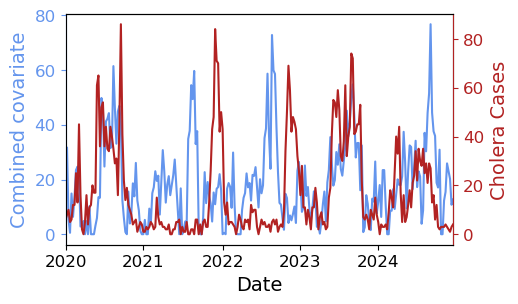

In [82]:
fig, ax = plt.subplots(figsize=(5, 3))
(
    df_reports_cov_xgbtree
    .set_index("date")
    .plot(
        y = "cov",
        ax = ax, 
        color = "cornflowerblue",
        legend = False
    )
)
ax2 = ax.twinx()
(
    df_reports_cov_xgbtree
    .set_index("date")
    .plot(
        y = "reports",
        ax = ax2, 
        legend = False,
        color = "firebrick"
    )
)
ax.set_ylabel("Combined covariate", fontsize = 14, color = "cornflowerblue")
ax.set(xticks=["2020-01-01", "2021-01-01", "2022-01-01", "2023-01-01", "2024-01-01"])
ax.set_xticklabels(["2020", "2021", "2022", "2023", "2024"], fontsize = 12) 
ax.set_xlabel("Date", fontsize = 14)
ax.spines["left"].set_color("cornflowerblue")
ax.tick_params(axis = "y", color = "cornflowerblue", labelsize = 12, labelcolor = "cornflowerblue")
ax2.set_ylabel("Cholera Cases", fontsize = 14, color = "firebrick")
ax2.spines["right"].set_color("firebrick")
ax2.tick_params(axis = "y", color = "firebrick", labelsize = 12, labelcolor = "firebrick")
plt.minorticks_off()
plt.savefig(img_dir / "combined_covariates_and_cholera.png", dpi = 300, bbox_inches = "tight")

## Output Data

In [131]:
df_reports_cov = df_reports_cov_xgb.copy()

In [132]:
df_reports_cov.head()

,date,reports,rdt_confirmed,idps,num_disaster_affected,covid_cases_per_million,covid_deaths_per_million,vacc,vacc_prop,cov,...,esi_6w,spei__cid_ce__normalize_True,rainfall_mm__kurtosis,spei_1w,esi__fourier_entropy__bins_100,"rainfall_mm__change_quantiles__f_agg_""mean""__isabs_False__qh_0.4__ql_0.0",esi__number_crossing_m__m_-1,num_fatalities__mean_change,spei_mean_8w,spei__fourier_entropy__bins_100
0,2020-01-03,6,0,0.0,0.0,0.0,0.0,0.0,0.0,28.657055,...,0.309006,0.533330,0.098005,-0.207273,1.0,0.030787,0.0,0.0,0.173186,1.0
1,2020-01-10,8,1,0.0,0.0,0.0,0.0,0.0,0.0,34.758129,...,0.298457,0.607873,0.438906,-0.190061,1.0,0.000000,0.0,0.0,0.128379,1.0
2,2020-01-17,10,1,0.0,0.0,0.0,0.0,0.0,0.0,26.222616,...,0.238054,0.974578,-0.842984,-0.094895,1.0,-0.025628,0.0,0.0,0.081539,1.0
3,2020-01-24,5,1,0.0,0.0,0.0,0.0,0.0,0.0,18.917818,...,0.326040,0.563045,-0.498685,0.000270,1.0,-0.025628,0.0,0.0,0.032667,1.0
4,2020-01-31,6,1,0.0,0.0,0.0,0.0,0.0,0.0,19.594477,...,0.526136,0.533868,-0.990913,0.095435,1.0,-0.025628,0.0,0.0,-0.010643,1.0


In [118]:
axes = df_reports_cov.set_index("date").plot(subplots = True, legend = False, figsize = (5, 5.5))
axes[0].set_ylabel("Reports", fontsize = 14)
axes[-1].set(xticks=["2020-01-01", "2021-01-01", "2022-01-01", "2023-01-01", "2024-01-01"])
axes[-1].set_xticklabels(["2020", "2021", "2022", "2023", "2024"], fontsize = 12) 
axes[-1].set_xlabel("Date", fontsize = 14)
for ax in axes:
    ax.tick_params(axis = "y", labelsize = 12)
plt.minorticks_off()
plt.subplots_adjust(hspace = 0.1)
fig = axes[0].get_figure()
fig.align_ylabels(axes)
plt.savefig(img_dir / "model_data.png", dpi = 300, bbox_inches = "tight")

Error in callback <function flush_figures at 0x330d16660> (for post_execute), with arguments args (),kwargs {}:


KeyboardInterrupt: 

In [133]:
OUTPUT_FILEDATE = pd.Timestamp("today").strftime("%Y%m%d")
df_reports_cov.to_csv(processed_data_dir / f"uvira_chol_cov_week_{OUTPUT_FILEDATE}.csv", index=False)

# Create Table of Model Summaries

In [87]:
df_summary = pd.DataFrame.from_dict(
    dict(
        Model = ["m_1", "m_2", "m_3", "m_4", "m_5", "m_6", "m_7", "m_8", "m_9", "m_10", "m_11", "nb_ar1", "SARIMA"],
        log_likelihood = [-910, -841, -842, -866, -997, -931, -866, -867, -865, -953, -893, -882, -862],
        parameter_number = [10, 11, 12, 11, 10, 11, 12, 13, 15, 15, 19, 3, 7],
    )
)
df_summary = (
    df_summary
    .assign(
        AIC = lambda x: round(2 * x["parameter_number"] - 2 * x["log_likelihood"], 2),
        # BIC = lambda x: round(x["parameter_number"] * np.log(df_reports_cov.shape[0]) - 2 * x["log_likelihood"], 2),
        # AICc = lambda x: round(
        #     x["AIC"] + (2 * x["parameter_number"] * (x["parameter_number"] + 1)) / (df_reports_cov.shape[0] - x["parameter_number"] - 1), 2
        # ),
        Delta_AIC = lambda x: round(x["AIC"] - x["AIC"].min(), 2),
        # Delta_BIC = lambda x: round(x["BIC"] - x["BIC"].min(), 2),
        # Delta_AICc = lambda x: round(x["AICc"] - x["AICc"].min(), 2),
    )
    # .set_index("Model")
    .drop(columns = ["AIC"])
    # .sort_values(by = "Delta_AIC")
)


In [88]:
df_summary

,Model,log_likelihood,parameter_number,Delta_AIC
0,m_1,-910,10,136
1,m_2,-841,11,0
2,m_3,-842,12,4
3,m_4,-866,11,50
4,m_5,-997,10,310
5,m_6,-931,11,180
6,m_7,-866,12,52
7,m_8,-867,13,56
8,m_9,-865,15,56
9,m_10,-953,15,232


In [89]:
cm = sns.light_palette("seagreen", as_cmap=True)
summary_table = (
    df_summary
    .rename(
        columns = {
            "log_likelihood": "Log Likelihood",
            "parameter_number": "# Parameters",
            "Delta_AIC": "Delta AIC"
        }
    )
    .style
    .background_gradient(
        cmap=sns.light_palette("turquoise", as_cmap=True), 
        subset=["Log Likelihood"]
    )
    .background_gradient(
        cmap=sns.light_palette("cornflowerblue", as_cmap=True), 
        subset=["# Parameters"]
    )
    .background_gradient(
        cmap=sns.light_palette("brown", as_cmap=True), 
        subset=["Delta AIC"]
    )
    .set_properties(**{"font-size": "14pt"})
    # .set_caption("Models Summary")
    .set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("font-size", "20pt"), 
                    ("text-align", "center"),
                    ("font-weight", "bold"),
                ],
            },
            {
                "selector": "th",
                "props": [("font-size", "14pt"), ("text-align", "center")],
            },
            {
                "selector": "td",
                "props": [("font-size", "14pt"), ("text-align", "right")],
            },
        ]
    )
    .hide(axis="index")
)
summary_table

Model,Log Likelihood,# Parameters,Delta AIC
m_1,-910,10,136
m_2,-841,11,0
m_3,-842,12,4
m_4,-866,11,50
m_5,-997,10,310
m_6,-931,11,180
m_7,-866,12,52
m_8,-867,13,56
m_9,-865,15,56
m_10,-953,15,232


In [90]:
imgkit.from_string(
    summary_table.to_html(),
    img_dir / "summary_table.png"
)

Loading page (1/2)
Rendering (2/2)                                                    
Done                                                               


True